# Разведочный анализ данных (EDA)
Проводится анализ распределений, поиск аномалий и изучение взаимосвязей между признаками.
## 1. Анализ распределения признаков
### 1.1. Числовые признаки
Исследуем форму распределения и наличие выбросов с помощью гистограмм и Boxplot.
## Загрузка данных и настройка

In [5]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

df = pd.read_csv('ML-Dataset_cleaned.csv')

# Основные числовые признаки для анализа
num_features = ['ProductStandardCost', 'Profit', 'ProductListPrice',
                'CustomerCreditLimit', 'OrderItemQuantity', 'Profit_Per_Unit']

# Настройка стиля графиков
sns.set_theme(style="whitegrid")

 ## Построение гистограмм и графиков плотности

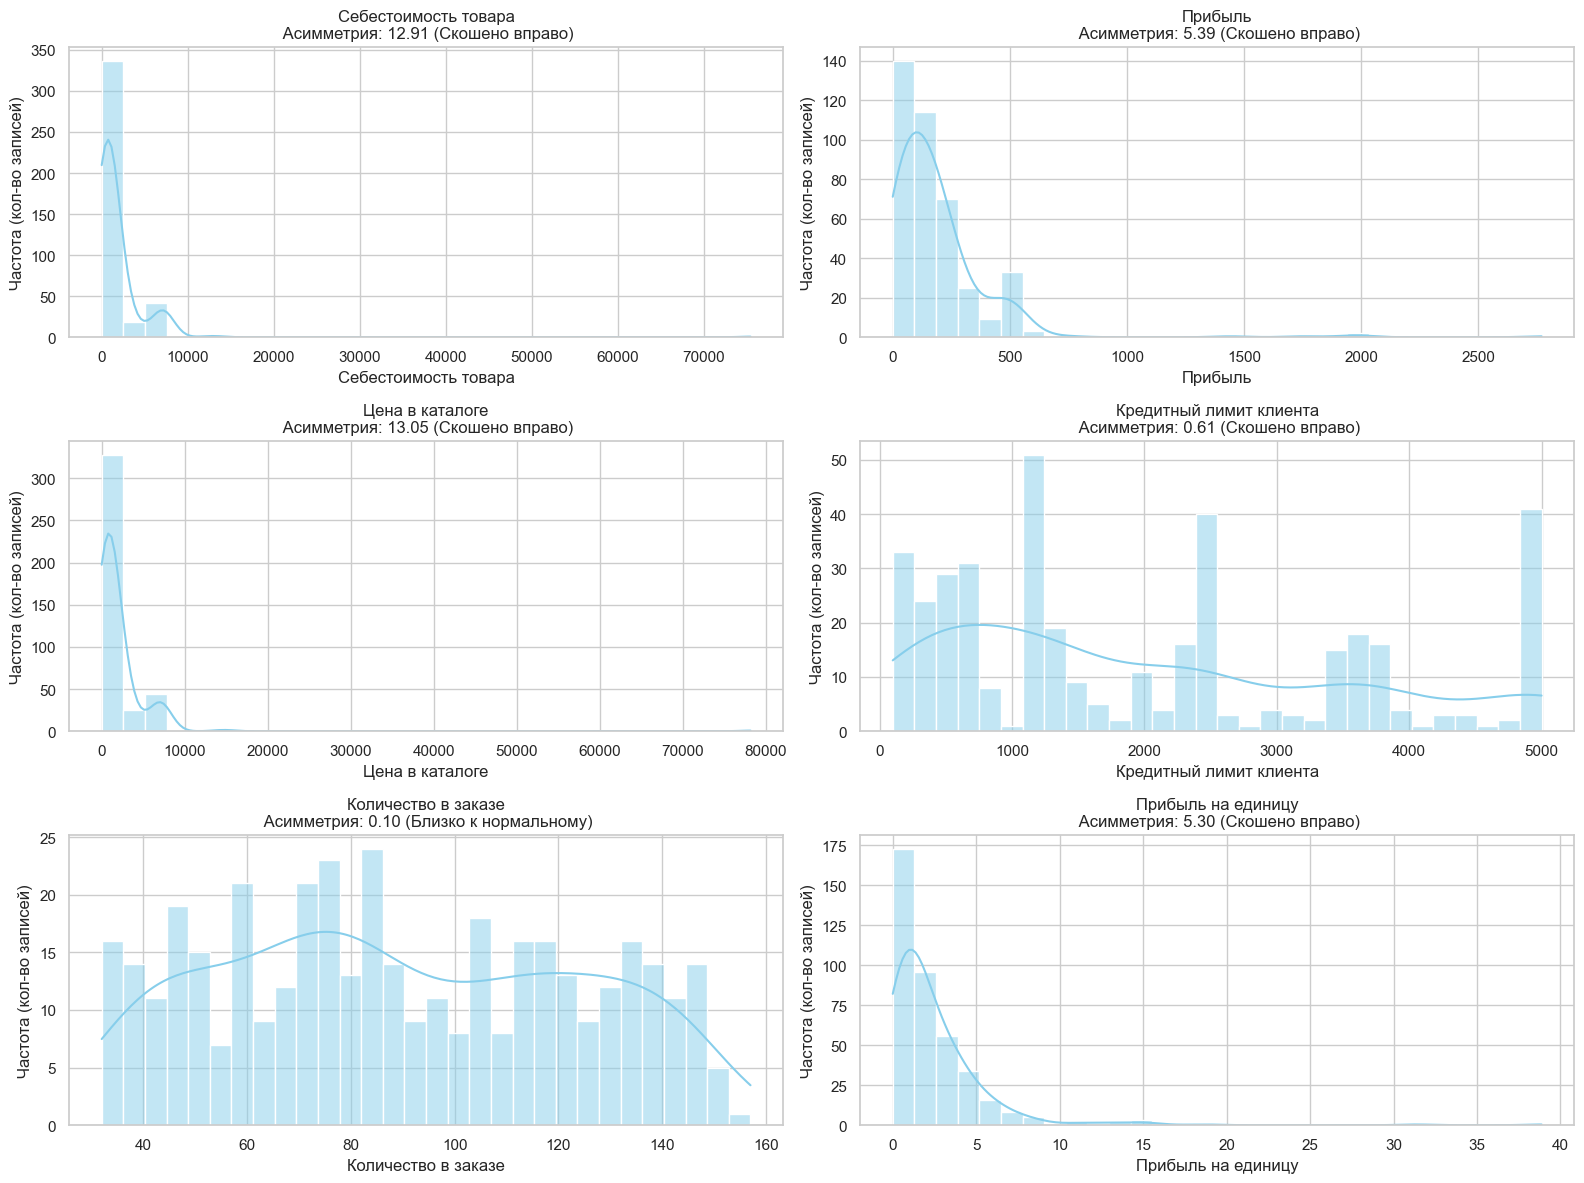

In [6]:
rus_names = {
    'ProductStandardCost': 'Себестоимость товара',
    'Profit': 'Прибыль',
    'ProductListPrice': 'Цена в каталоге',
    'CustomerCreditLimit': 'Кредитный лимит клиента',
    'OrderItemQuantity': 'Количество в заказе',
    'Profit_Per_Unit': 'Прибыль на единицу'
}

# Построение гистограмм
plt.figure(figsize=(16, 12))
for i, col in enumerate(num_features, 1):
    plt.subplot(3, 2, i)
    # Строим график
    sns.histplot(df[col], kde=True, color='skyblue', bins=30)

    # Расчет асимметрии
    skewness = df[col].skew()
    if skewness > 0.5:
        shape = "Скошено вправо"
    elif skewness < -0.5:
        shape = "Скошено влево"
    else:
        shape = "Близко к нормальному"
    title_rus = rus_names.get(col, col)

    plt.title(f'{title_rus}\n Асимметрия: {skewness:.2f} ({shape})', fontsize=12)
    plt.xlabel(title_rus)
    plt.ylabel('Частота (кол-во записей)')

plt.tight_layout()
plt.show()

## Построение диаграмм «ящик с усами» для определения выбросов

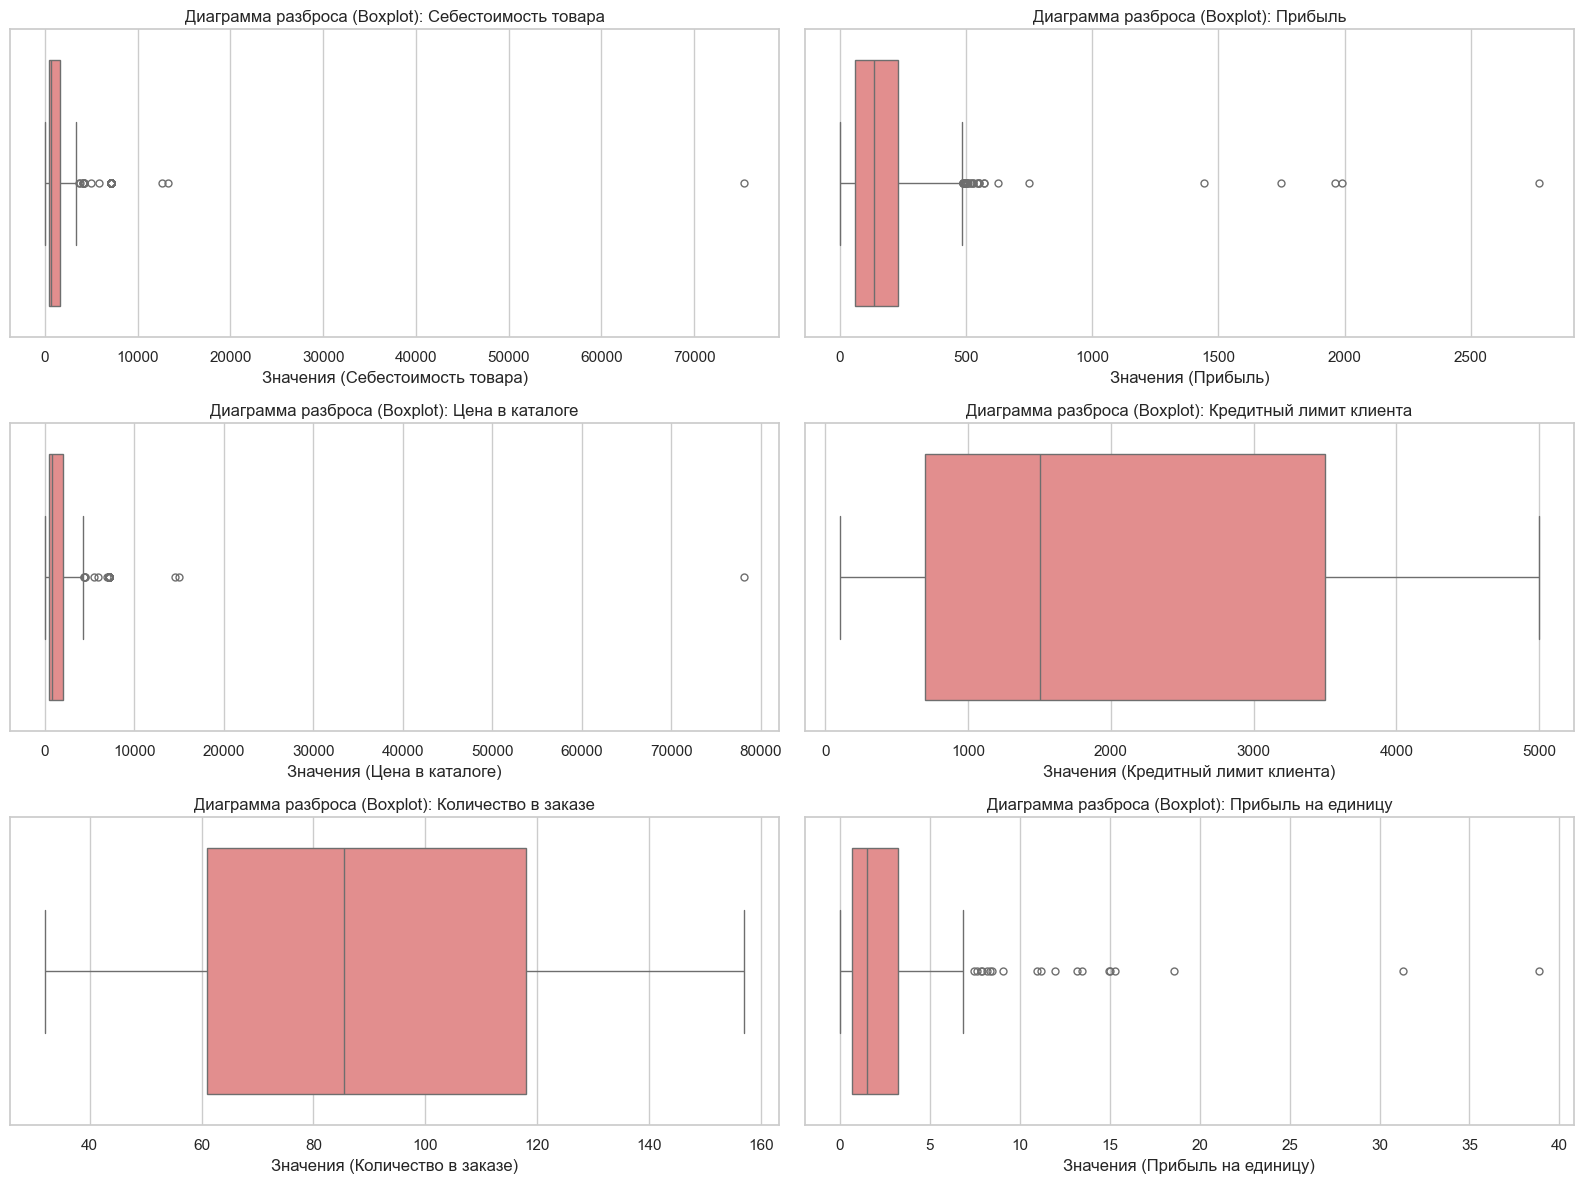

Анализ выбросов:
- ProductStandardCost: обнаружено 54 выбросов (границы: -1472.53 - 3558.64)
- Profit: обнаружено 30 выбросов (границы: -194.35 - 483.84)
- ProductListPrice: обнаружено 51 выбросов (границы: -1742.38 - 4245.25)
- CustomerCreditLimit: обнаружено 0 выбросов (границы: -3500.00 - 7700.00)
- OrderItemQuantity: обнаружено 0 выбросов (границы: -24.50 - 203.50)
- Profit_Per_Unit: обнаружено 19 выбросов (границы: -3.13 - 7.06)


In [7]:
# Построение диаграмм «ящик с усами»
plt.figure(figsize=(16, 12))
for i, col in enumerate(num_features, 1):
    plt.subplot(3, 2, i)
    # Строим график
    sns.boxplot(x=df[col], color='lightcoral', fliersize=5)
    title_rus = rus_names.get(col, col)
    plt.title(f'Диаграмма разброса (Boxplot): {title_rus}', fontsize=12)
    plt.xlabel(f'Значения ({title_rus})')
plt.tight_layout()
plt.show()

#Вывод статистики по выбросам (метод IQR)
print("Анализ выбросов:")
for col in num_features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    print(f"- {col}: обнаружено {len(outliers)} выбросов (границы: {lower_bound:.2f} - {upper_bound:.2f})")

## Обработка признаков и устранение аномалий

Что было сделано:
1. Логарифмирование (Log1p): Применено к признакам Цена продажи и Себестоимость.
2. Винзоризация (Clip): Значения Прибыли и Прибыли на единицу ограничены по верхним и нижним границам.
3. Синхронизация названий: Созданы производные признаки (например, Log_ProductListPrice), чтобы сохранить исходные данные для сравнения.

Для чего это сделано:

1. Нормализация распределения: Логарифмирование «сжало» длинные правые хвосты в ценах. Это превратило скошенные данные в близкие к нормальным.
2. Повышение устойчивости модели: Устранение экстремальных выбросов в прибыли (с 50+ до 0–10).
3. Масштабирование: Мы привели разные по величине признаки (цены в тысячах и количество в десятках) к более сопоставимому масштабу.

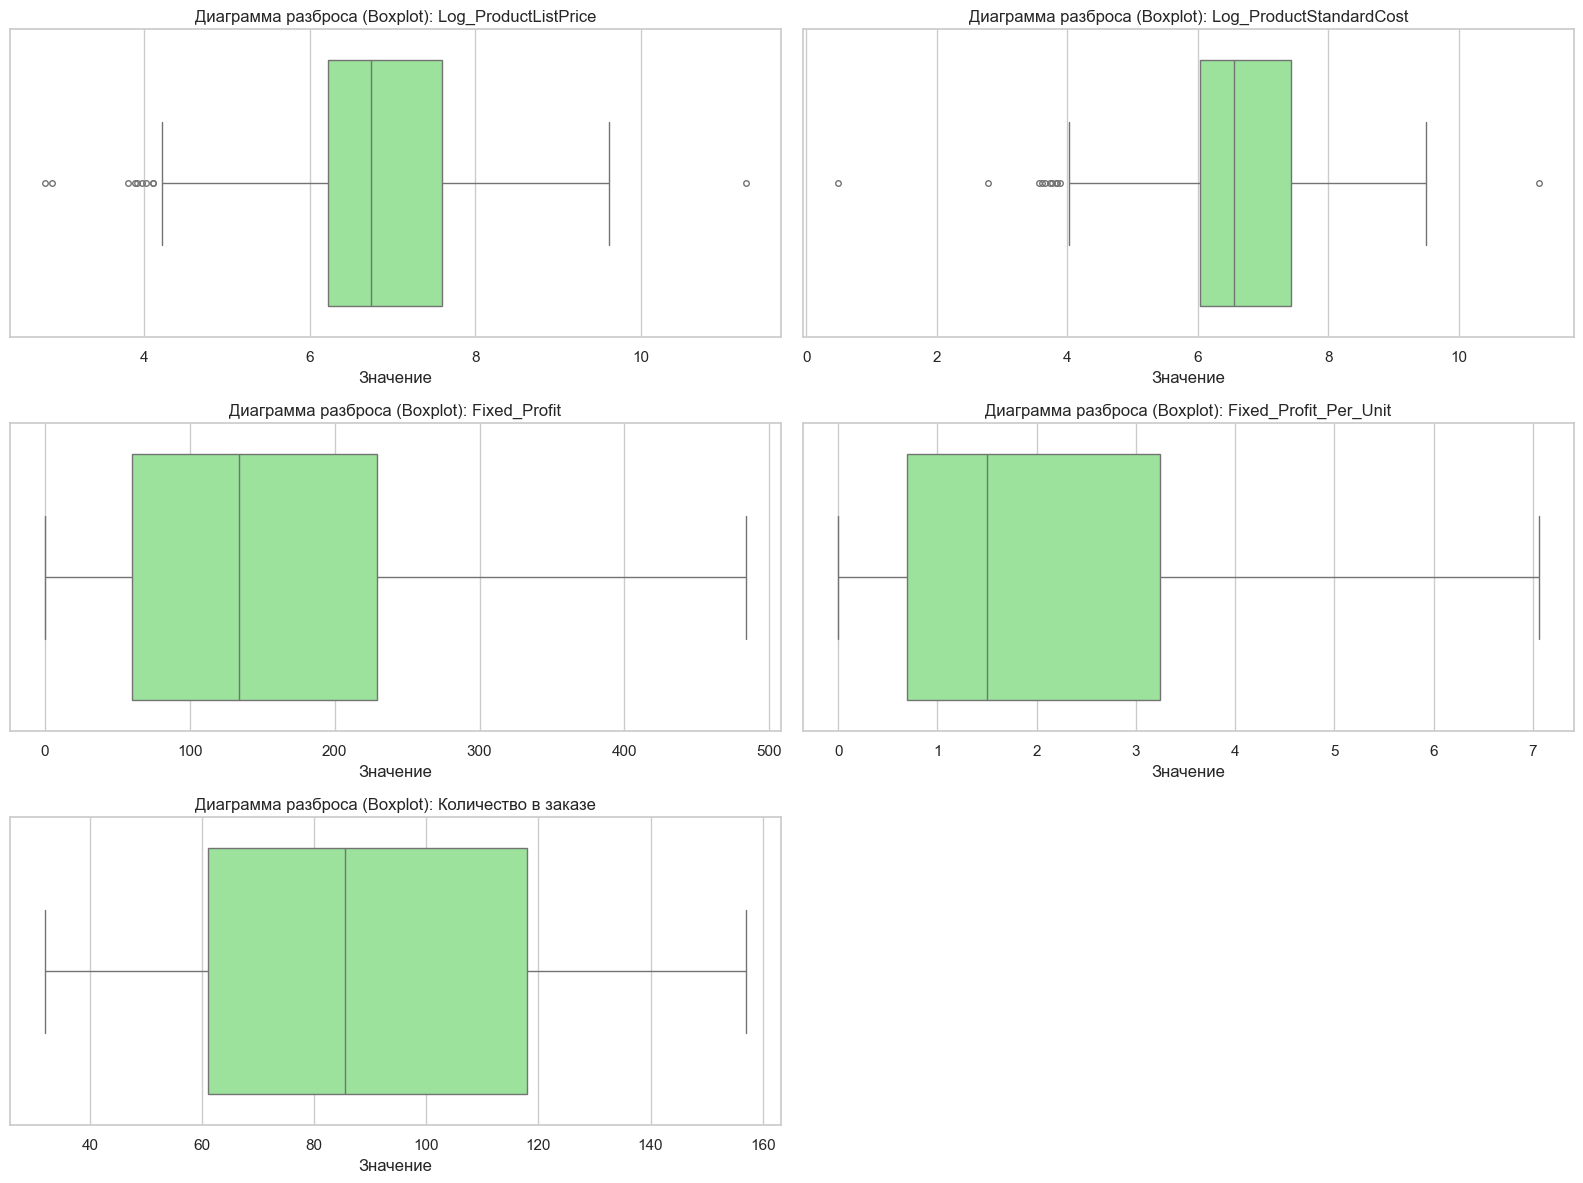

После всех исправлений
• Log_ProductListPrice.....: осталось 10 выбросов
• Log_ProductStandardCost..: осталось 11 выбросов
• Fixed_Profit.............: осталось 0 выбросов
• Fixed_Profit_Per_Unit....: осталось 0 выбросов
• Количество в заказе......: осталось 0 выбросов


In [16]:
# Исправленные данных
df['Log_ProductListPrice'] = np.log1p(df['ProductListPrice'])
df['Log_ProductStandardCost'] = np.log1p(df['ProductStandardCost'])
df['Fixed_Profit'] = df['Profit'].clip(upper=483.84)
df['Fixed_Profit_Per_Unit'] = df['Profit_Per_Unit'].clip(lower=-3.13, upper=7.06)

# Визуализация
final_features = ['Log_ProductListPrice', 'Log_ProductStandardCost',
                  'Fixed_Profit', 'Fixed_Profit_Per_Unit', 'OrderItemQuantity']
plt.figure(figsize=(16, 12))

for i, col in enumerate(final_features, 1):
    plt.subplot(3, 2, i)
    # Строим ящик с усами для исправленных данных
    sns.boxplot(x=df[col], color='lightgreen', fliersize=4)
    title_rus = rus_names.get(col, col)
    plt.title(f'Диаграмма разброса (Boxplot): {title_rus}', fontsize=12)
    plt.xlabel('Значение')
plt.tight_layout()
plt.show()

print("После всех исправлений")
for col in final_features:
    Q1, Q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    IQR = Q3 - Q1
    outliers = len(df[(df[col] < Q1 - 1.5 * IQR) | (df[col] > Q3 + 1.5 * IQR)])
    print(f"• {rus_names.get(col, col):.<25}: осталось {outliers} выбросов")

### 1.2. Категориальные признаки
Оценим частоту встречаемости различных категорий в данных.

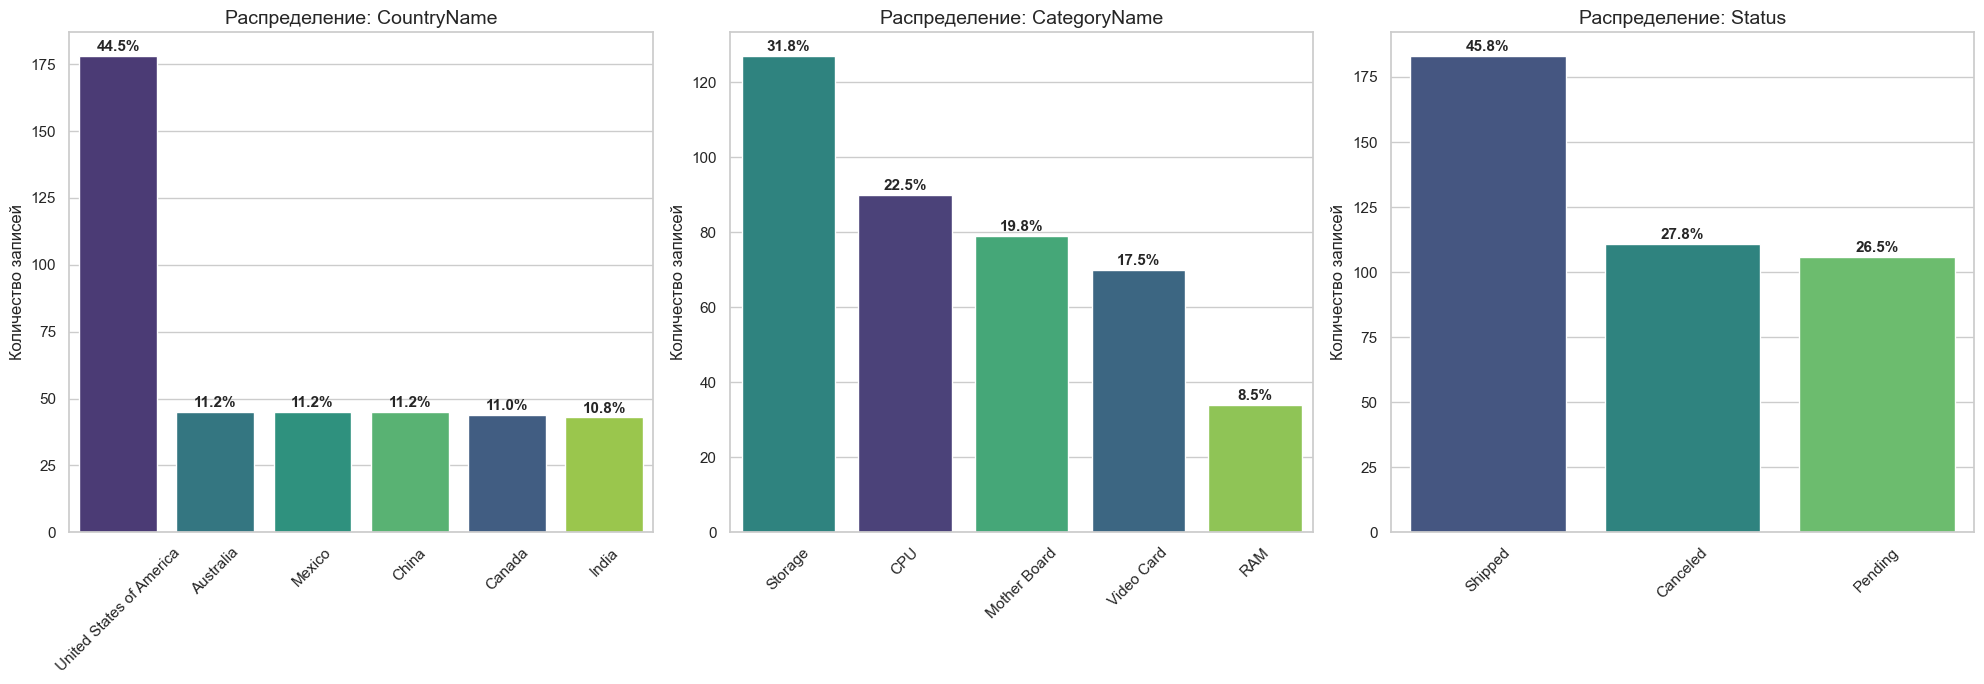


Признак 'CountryName':
- Самая частая категория: United States of America (44.5%)
- Количество уникальных значений: 6

Признак 'CategoryName':
- Самая частая категория: Storage (31.8%)
- Количество уникальных значений: 5

Признак 'Status':
- Самая частая категория: Shipped (45.8%)
- Количество уникальных значений: 3


In [17]:
# Настройка списка признаков
cat_features = ['CountryName', 'CategoryName', 'Status']

# Создаем сетку графиков (1 строка, 3 колонки)
plt.figure(figsize=(20, 7))
for i, col in enumerate(cat_features, 1):
    plt.subplot(1, 3, i)
    order = df[col].value_counts().index
    # Строим график
    ax = sns.countplot(data=df, x=col, order=order, hue=col, palette='viridis', legend=False)

    # Добавляем проценты над каждым столбцом
    total = len(df[col])
    for p in ax.patches:
        percentage = f'{100 * p.get_height() / total:.1f}%'
        x = p.get_x() + p.get_width() / 2
        y = p.get_height() + (max(df[col].value_counts()) * 0.01) # Небольшой отступ сверху
        ax.annotate(percentage, (x, y), ha='center', fontsize=11, fontweight='bold')
    plt.title(f'Распределение: {col}', fontsize=14)
    plt.xticks(rotation=45)
    plt.xlabel('')
    plt.ylabel('Количество записей')
plt.tight_layout()
plt.show()

for col in cat_features:
    counts = df[col].value_counts()
    top_cat = counts.idxmax()
    top_perc = (counts.max() / len(df)) * 100
    print(f"\nПризнак '{col}':")
    print(f"- Самая частая категория: {top_cat} ({top_perc:.1f}%)")
    print(f"- Количество уникальных значений: {df[col].nunique()}")

## 2. Анализ взаимосвязей между признаками
Построим матрицу корреляции и диаграммы рассеяния для поиска зависимостей.

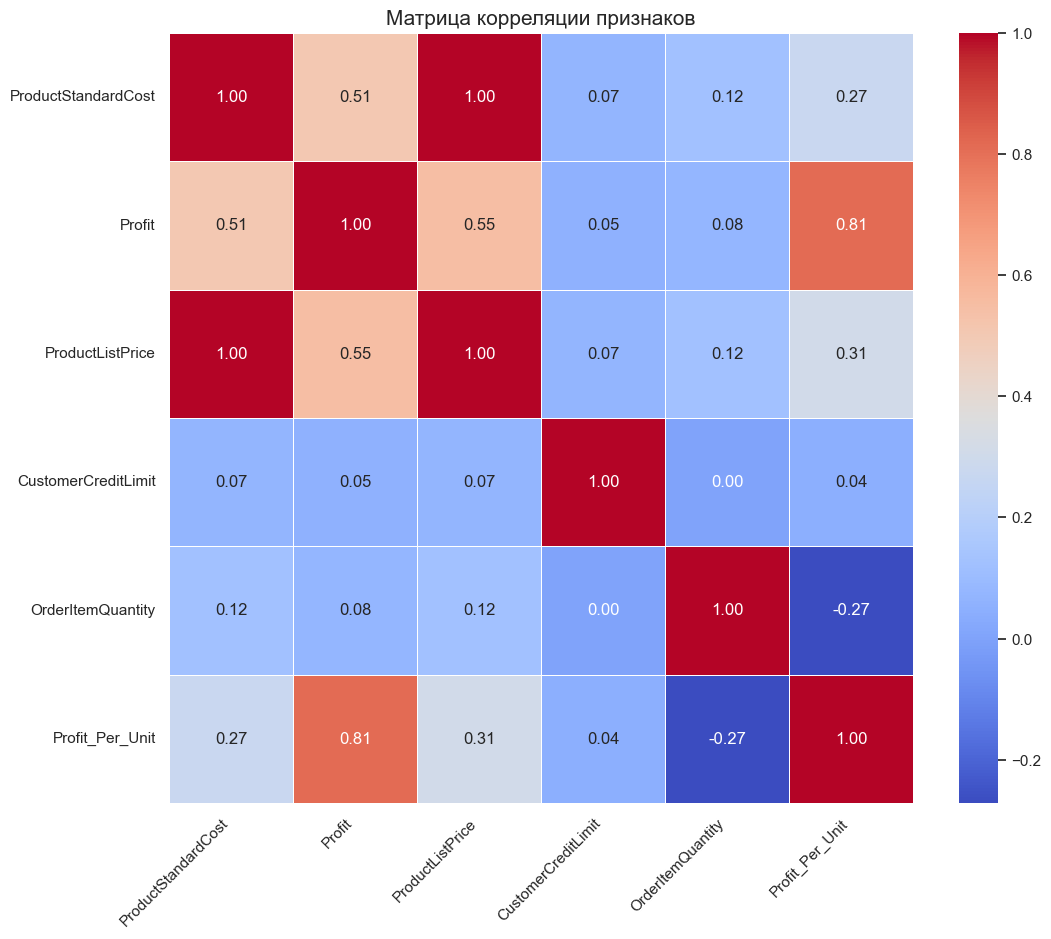

In [20]:
# Визуализация матрицы корреляции с помощью тепловой карты
plt.figure(figsize=(12, 10))
numeric_df = df[['ProductStandardCost', 'Profit', 'ProductListPrice',
                 'CustomerCreditLimit', 'OrderItemQuantity', 'Profit_Per_Unit']]
corr_matrix = numeric_df.corr()

# Строим тепловую карту
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Матрица корреляции признаков', fontsize=15)
plt.xticks(rotation=45, ha='right')
plt.show()

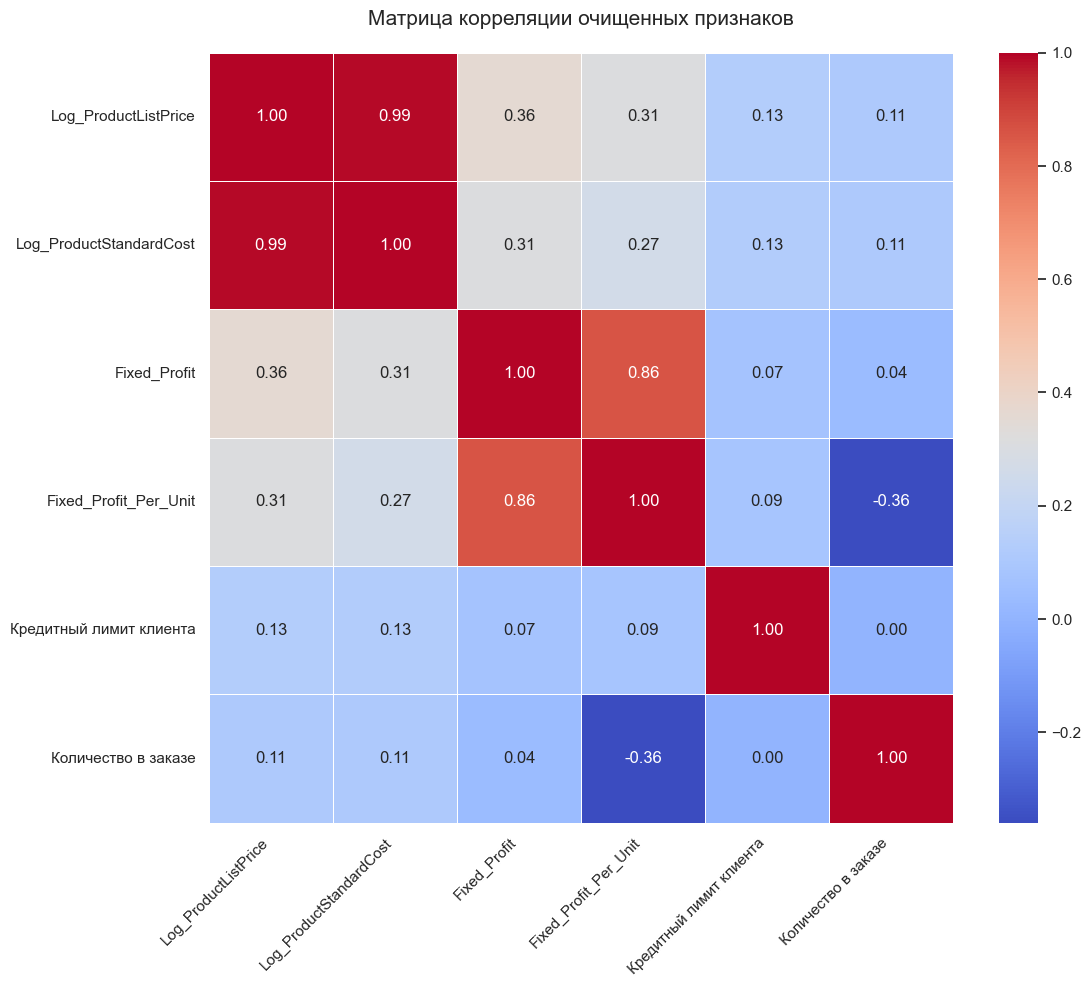

In [19]:
# Выбираем исправленные признаки для корректного анализа
cleaned_numeric_df = df[['Log_ProductListPrice', 'Log_ProductStandardCost',
                         'Fixed_Profit', 'Fixed_Profit_Per_Unit',
                         'CustomerCreditLimit', 'OrderItemQuantity']]
corr_matrix = cleaned_numeric_df.corr()
labels_rus = [rus_names.get(col, col) for col in corr_matrix.columns]
#Строим тепловую карту
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, xticklabels=labels_rus, yticklabels=labels_rus)
plt.title('Матрица корреляции очищенных признаков', fontsize=15, pad=20)
plt.xticks(rotation=45, ha='right')
plt.show()

# 2.2. Определение пар с высокой корреляцией

In [21]:
# Определение пар с высокой корреляцией
print("Пары признаков с высокой корреляцией (|r| > 0.7):")
corr_unstacked = corr_matrix.unstack().sort_values(ascending=False)
# Убираем корреляцию признака самого с собой (1.0) и дубликаты
high_corr = corr_unstacked[(abs(corr_unstacked) > 0.7) & (abs(corr_unstacked) < 1.0)]
print(high_corr.drop_duplicates())

Пары признаков с высокой корреляцией (|r| > 0.7):
ProductStandardCost  ProductListPrice    0.998778
Profit_Per_Unit      Profit              0.814898
dtype: float64


# 2.3. Диаграммы рассеяния для наиболее коррелированных пар

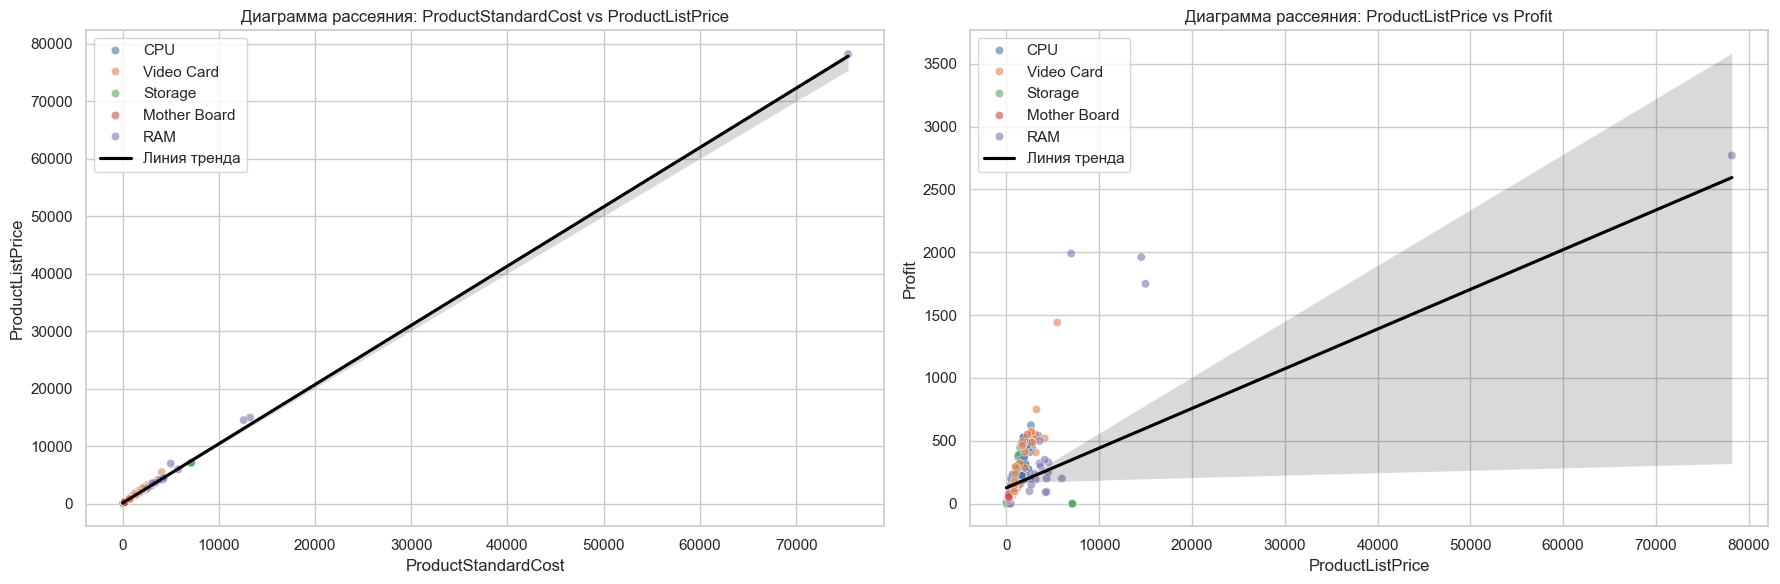

In [23]:
# Диаграммы рассеяния  для наиболее коррелированных пар
target_pairs = [
    ('ProductStandardCost', 'ProductListPrice'),
    ('ProductListPrice', 'Profit')
]
plt.figure(figsize=(18, 6))

for i, (x_col, y_col) in enumerate(target_pairs, 1):
    plt.subplot(1, 2, i)
    # Используем CategoryName для раскраски точек
    sns.scatterplot(data=df, x=x_col, y=y_col, hue='CategoryName', alpha=0.6)
    # Добавляем линию тренда
    sns.regplot(data=df, x=x_col, y=y_col, scatter=False, color='black', label='Линия тренда')
    plt.title(f'Диаграмма рассеяния: {x_col} vs {y_col}')
    plt.legend()
plt.tight_layout()
plt.show()

## 3. Основные выводы
В данных наблюдается сильный дисбаланс в целевом статусе (Shipped >> Canceled).
* Статус Canceled составляет меньшинство, что критично для обучения классификаторов.

Большинство финансовых показателей имеют правосторонний скос (много дешевых товаров, мало очень дорогих).
* Это говорит о том, что основной оборот компании идет за счет товаров среднего ценового сегмента

Сильная зависимость цен: Себестоимость `ProductStandardCost` и цена продажи `ProductListPrice` практически линейно зависимы, что указывает на стабильную стратегию наценки.

## 4. Закономерности и аномалии
* **Взаимозависимость:** Обнаружена почти линейная связь (0.98) между `StandardCost`(Себестоимость) и `ListPrice`(Цена). Использование обоих признаков в модели избыточно.

* **Связь прибыли и объема:** Общая прибыль (Profit) больше зависит от количества проданного товара `OrderItemQuantity`, чем от цены единицы, что характерно для оптовой торговли комплектующими.

* **Аномалии:** В признаке `Profit_Per_Unit` присутствуют выбросы, которые могут быть связаны с ошибками ввода или специфическими акциями. Выявлены выбросы в Profit_Per_Unit, превышающие среднее значение в несколько раз.

## 5. Рекомендации по подготовке данных
* **Удаление:** Рекомендуется удалить `ProductStandardCost`, так как он дублирует информацию из `ProductListPrice`. Это упростит модель и уберет взаимозависимость.
* **Трансформация:** Применить логарифмирование для `Profit` и `ProductListPrice`, чтобы нормализовать распределение.
* **Обработка выбросов:** Возможно заменить экстремальных значений на пороговые или удаления записей, где прибыль на единицу имеет отрицательные значения.
* **Кодирование:** Для `CategoryName` использовать One-Hot Encoding, для `CountryName` — Target Encoding.

## 6. Гипотезы
1. Порог отмены: Существует критический объем заказа (OrderItemQuantity), после которого вероятность отмены резко возрастает.
2. Устойчивость категорий: Категория CPU демонстрирует более стабильную маржинальность в разных регионах по сравнению с Video Cards.
5. Высокая корреляция Profit и OrderItemQuantity предполагает зависимость от объема заказов

//
3. Региональная специфика: Средняя прибыль на единицу товара в Индии ниже, чем в США, при равных объемах продаж.
4. Кредитный фактор: Клиенты с кредитным лимитом $> 3000$ чаще совершают высокодоходные сделки.

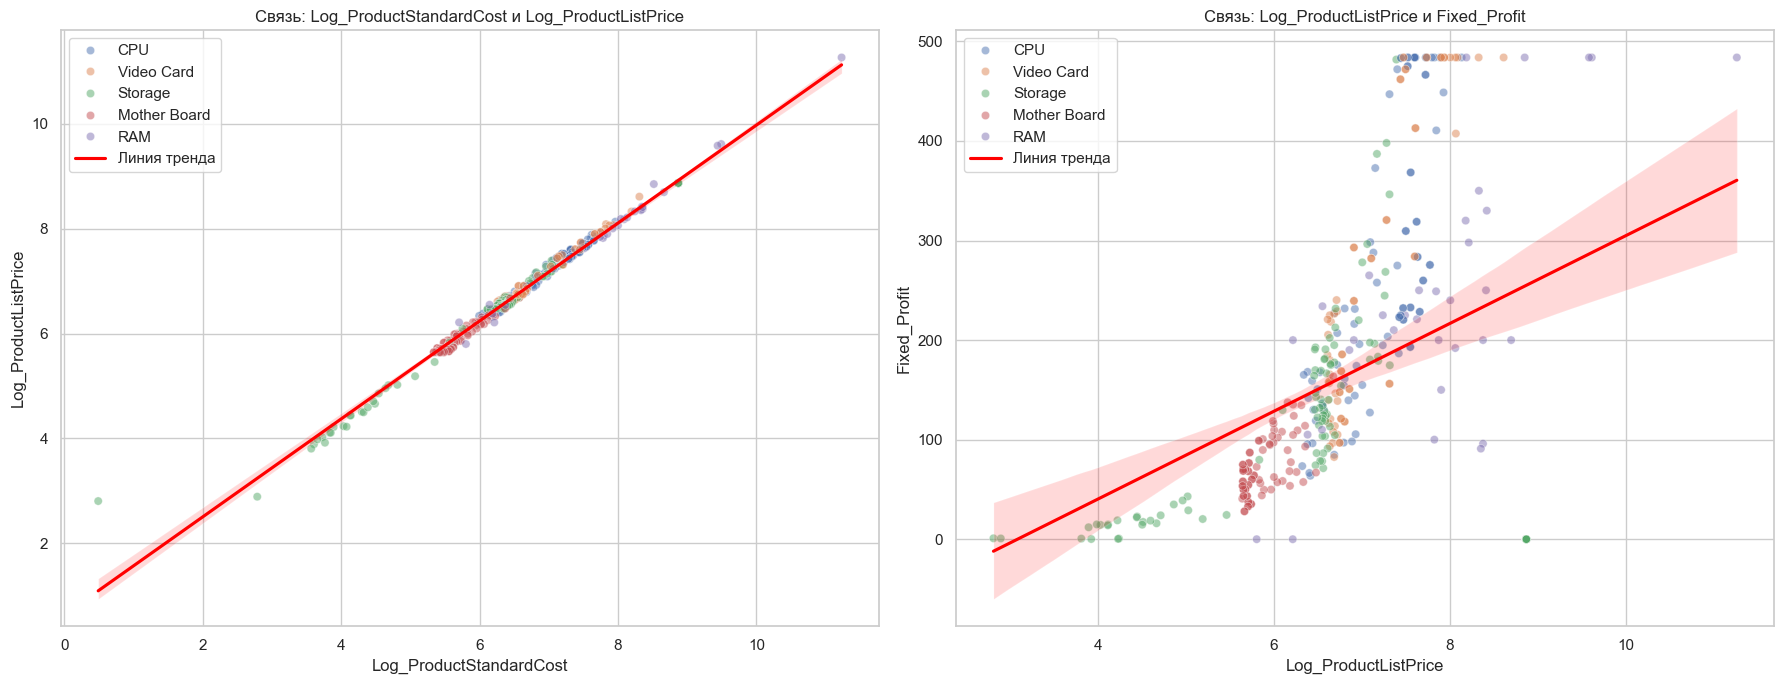

In [22]:
# Очищенные и логарифмированные данные для честной визуализации
target_pairs = [
    ('Log_ProductStandardCost', 'Log_ProductListPrice'),
    ('Log_ProductListPrice', 'Fixed_Profit')
]
plt.figure(figsize=(18, 7))
for i, (x_col, y_col) in enumerate(target_pairs, 1):
    plt.subplot(1, 2, i)
    sns.scatterplot(data=df, x=x_col, y=y_col, hue='CategoryName', alpha=0.5)
    sns.regplot(data=df, x=x_col, y=y_col, scatter=False, color='red', label='Линия тренда')
    plt.title(f'Связь: {rus_names.get(x_col, x_col)} и {rus_names.get(y_col, y_col)}')
    plt.legend()
plt.tight_layout()
plt.show()

In [2]:
# НЕ берем старую себестоимость и сырые цены, чтобы не забивать новый файл
new_columns = [
    'Log_ProductListPrice',    # Исправленная цена
    'Fixed_Profit',            # Исправленная прибыль
    'Fixed_Profit_Per_Unit',   # Исправленная маржа
    'OrderItemQuantity',       # Количество
    'CustomerCreditLimit',     # Кредит
    'CountryName',             # Категории (для кодирования)
    'CategoryName',
    'Status'
]
df_cleaned = df[new_columns].copy()
# Сохраняем
output_filename = 'ML-Dataset_lab_2.csv'
df_cleaned.to_csv(output_filename, index=False)
print(f"Создан новый датасет: {output_filename}")
print(f"Размер нового файла: {df_cleaned.shape[0]} строк и {df_cleaned.shape[1]} колонок")

NameError: name 'df' is not defined

# Ответы на вопросы по теме:

### 1. Что такое разведочный анализ данных(EDA)?
**EDA** – это подход к анализу данных,  изучая набор данных для понимания его структуры, выявления закономерностей и проверки гипотез.

**Цель:** Это помогает убедиться, что данные корректны, а выбранные методы анализа адекватны.

### 2. Почему EDA важен и какие преимущества он дает?
Без EDA модель обучается на "шуме".
* **Преимущества:**
  1. Предотвращает ошибки (gigo).
  2. Помогает найти скрытые зависимости.
  3. Позволяет обоснованно выбрать стратегию обработки пропусков.
  4. Улучшает точность моделей за счет качественного отбора признаков.

### 3. Какие основные задачи решаются в процессе EDA?
1. Оценка качества данных (пропуски, дубликаты).
2. Анализ распределений (нормальное, смещенное).
3. Поиск аномалий и выбросов.
4. Исследование корреляций между признаками и целевой переменной.

### 4. Методы и техники EDA
* **Статистические:** корреляционная матрица.
* **Визуальные:** Гистограммы, Boxplots, Scatter plots.

### 5. Как оценить влияние пропущенных данных и выбросов?
1. **Пропуски:** Если их >50%, признак часто бесполезен. Если <5%, их можно удалить без потери значимости.
2. **Выбросы:** Сравните среднее и медиану. Если они сильно различаются — выбросы смещают "центр" данных.
3. **Модели:** Линейные модели (Linear Regression) крайне чувствительны к выбросам, в то время как древовидные (Random Forest) — почти нет.